In [1]:
import scipy.io as sio
import pickle
import matplotlib.pyplot as plt
import numpy as np
import sys
sys.path.append('../../')
from helper_function import *
cobra.Configuration.solver = 'glpk'

In [3]:
cmap = plt.get_cmap('coolwarm')
num_colors = 20
colors = [cmap(i / num_colors) for i in range(num_colors)]

set_color = colors[3] #17 18
scatter_color = colors[2] #3 2


with open('../../FBAsolution/M9_sufficient_20_40_proteome.pkl', 'rb') as pickle_file:
    data = pickle.load(pickle_file)
    all_total_nutrient_count = data['all_total_nutrient_count']
    all_total_intake = data['all_total_intake']
    all_growth_rate = data['all_growth_rate']
    all_random_medium = data['all_random_medium']
    all_met_flux = data['all_met_flux']
    del data

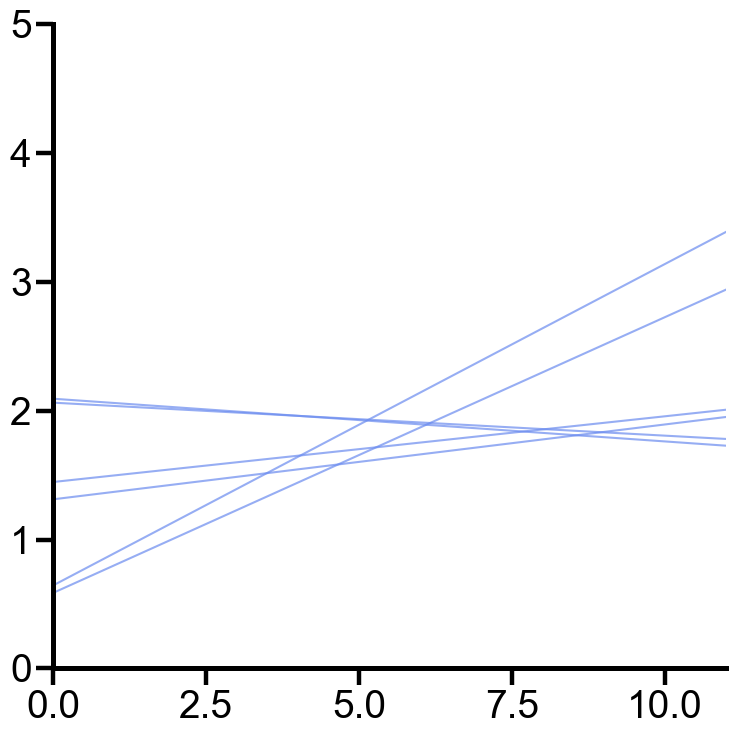

In [4]:
set_panel_style(scale=4)

visualized_index = [2, 18, 24, 30, 7, 9]

total_slope = []


plt.figure(figsize=(8, 8))
ax = plt.gca()

x_max_all = 0.0
for i in visualized_index:
    mask = all_growth_rate[i] > 0.001
    if np.any(mask):
        xi = all_total_nutrient_count[i][mask]
        if len(xi) > 0:
            x_max_all = max(x_max_all, float(np.max(xi)))

xx = np.linspace(0, x_max_all + 1, 200)

for i in visualized_index:
    mask = all_growth_rate[i] > 0.001
    x = all_total_nutrient_count[i][mask]
    y = all_growth_rate[i][mask]

    if len(x) < 2:
        continue

    try:
        slope, intercept = np.polyfit(x, y, 1)
        yy = slope * xx + intercept
        ax.plot(xx, yy, color=set_color, alpha=0.7, linewidth=1.5)
        total_slope.append(slope)
    except Exception:
        continue

# Axes limits
ax.set_xlim(0, x_max_all + 1)
ax.set_ylim(0, 5)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)


plt.tight_layout()
#plt.savefig("Figure1b_2.pdf", format="pdf", pad_inches=0.5)
plt.show()